# Model 1 · Fine-tuning Pipeline 1 (understand tonight's request)

**App:** Same Table / 糖友同枱 — one shared home dinner for a diabetes patient and the family.
**Pipeline 1** turns the cook's sentence into 8 tags that drive the menu:
`steam, blanch, soup, stir, more_veg, more_meat, less_sweet, quick`. It is the pipeline closest to the
project objective, so it is the one we fine-tune.

Steps in this notebook
1. Load our dataset (3,000 training / 600 evaluation / 108 hand-written test sentences).
2. Baselines without training: keyword lexicon and a zero-shot model.
3. Fine-tune **three comparable pre-trained models** with identical settings.
4. Compare **accuracy** (`trainer.evaluate()`) and **run time**; pick one.
5. Final test of the picked model on the hand-written sentences; save and upload it.

## 0 · Setup

In [1]:
# Runs in Colab ("Restart & Run All") and locally. Clones the project if it is not already here.
import gc, json, os, random, subprocess, sys, time, warnings
from pathlib import Path

REPO_URL = "https://github.com/Tannedfish/same-table.git"
here = Path.cwd()
if not any((p / "same_table").is_dir() for p in (here, here.parent)):
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "same-table"], check=True)
    os.chdir("same-table")
ROOT = Path.cwd() if (Path.cwd() / "same_table").is_dir() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

try:
    import datasets, sentence_transformers, sklearn, transformers  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets",
                    "sentence-transformers", "scikit-learn", "accelerate", "openpyxl"], check=True)

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

DATA, OUT = ROOT / "data" / "train", ROOT / "artifacts"
OUT.mkdir(exist_ok=True)
HF_USER = "Tannedfish"            # Hugging Face username that owns the fine-tuned model
SEED = 5240

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]

set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

PUSH_TO_HUB = False               # set True after `from huggingface_hub import login; login()`
RUN_ZERO_SHOT = True              # zero-shot baseline: about 2 minutes on CPU

/usr/local/lib/python3.11/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.14.1+cpu


## 1 · Dataset

* **Labels:** 8 tags, multi-label (a sentence can carry several tags, or none).
* **Feature:** the request text (Cantonese, Mandarin or English).
* **Training / evaluation:** generated by `scripts/make_training_data.py` from phrase banks written for this
  project. The evaluation split is built **only from phrases held out of training**, so
  `trainer.evaluate()` scores wording the model has never seen.
* **Test:** 108 sentences written by hand in free form. They are never used for training or model choice.

In [2]:
from same_table.tagging import ALL_TAGS, keyword_tags

if not (DATA / "p1_eval.jsonl").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "make_training_data.py")], check=True)

p1_train, p1_eval, p1_test = (read_jsonl(DATA / f"p1_{name}.jsonl") for name in ("train", "eval", "test"))

def onehot(rows):
    return np.array([[float(t in r["tags"]) for t in ALL_TAGS] for r in rows], dtype=np.float32)

Y_train, Y_eval, Y_test = onehot(p1_train), onehot(p1_eval), onehot(p1_test)
print(f"labels={len(ALL_TAGS)}  training={len(p1_train)}  evaluation={len(p1_eval)}  testing={len(p1_test)} (hand-written)")
pd.DataFrame({"training": Y_train.sum(0), "evaluation": Y_eval.sum(0), "testing": Y_test.sum(0)}, index=ALL_TAGS).astype(int).T

labels=8  training=3000  evaluation=600  testing=108 (hand-written)


,steam,blanch,soup,stir,more_veg,more_meat,less_sweet,quick
training,554,587,589,580,519,530,607,590
evaluation,106,130,103,89,109,108,136,109
testing,23,18,25,19,18,15,20,20


In [3]:
pd.DataFrame(p1_train[:3] + p1_eval[:3] + p1_test[:3], index=["training"] * 3 + ["evaluation"] * 3 + ["testing"] * 3)

,text,tags
training,肉多啲 and 來碗湯，熱炒一盤呀,"[more_meat, soup, stir]"
training,今日without sugar and need it fast,"[less_sweet, quick]"
training,隔水蒸 and 阿爸血糖高，同埋炒兩味，得唔得,"[less_sweet, steam, stir]"
evaluation,今晚爆炒。lots of meat。沒時間，得唔得,"[more_meat, quick, stir]"
evaluation,tonight 怕甜，仲有今晚要有湯,"[less_sweet, soup]"
evaluation,阿媽話今晚要有湯,[soup]
testing,阿爸牙唔好，想食啲軟熟嘅蒸餸，唔好太甜,"[less_sweet, steam]"
testing,今晚好趕，求其炒兩個餸就算,"[quick, stir]"
testing,想煲湯，另外加個白灼菜,"[blanch, soup]"


## 2 · Metrics and baselines

**Accuracy** = share of sentences where *all 8 tags* are right (exact match). It is strict: one wrong tag
makes the whole sentence wrong. **Tag accuracy** (share of the 8 yes/no decisions that are right) and
macro-F1 are shown as second views.

In [4]:
from sklearn.metrics import f1_score

def accuracy(y_true, y_pred):
    return float((np.asarray(y_true) == np.asarray(y_pred)).all(axis=1).mean())

def tag_accuracy(y_true, y_pred):
    """Share of individual tag decisions that are right (8 per sentence)."""
    return float((np.asarray(y_true) == np.asarray(y_pred)).mean())

def macro_f1(y_true, y_pred):
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))

def keyword_predict(rows):
    return np.array([[float(t in keyword_tags(r["text"])) for t in ALL_TAGS] for r in rows])

t0 = time.perf_counter(); kw_eval = keyword_predict(p1_eval); kw_seconds = time.perf_counter() - t0
kw_test = keyword_predict(p1_test)
baselines = {"keyword lexicon (no model)": {
    "eval_accuracy": accuracy(Y_eval, kw_eval), "eval_tag_accuracy": tag_accuracy(Y_eval, kw_eval), "eval_macro_f1": macro_f1(Y_eval, kw_eval),
    "test_accuracy": accuracy(Y_test, kw_test), "test_tag_accuracy": tag_accuracy(Y_test, kw_test), "test_macro_f1": macro_f1(Y_test, kw_test),
    "params_M": 0.0, "eval_seconds": kw_seconds}}
baselines["keyword lexicon (no model)"]

{'eval_accuracy': 0.3983333333333333,
 'eval_tag_accuracy': 0.90875,
 'eval_macro_f1': 0.6599535138265898,
 'test_accuracy': 0.6481481481481481,
 'test_tag_accuracy': 0.9537037037037037,
 'test_macro_f1': 0.8214080723671517,
 'params_M': 0.0,
 'eval_seconds': 0.025338785999338143}

In [5]:
from transformers import pipeline
from same_table.config import DEFAULT_P1_MODEL
from same_table.tagging import HYPOTHESIS, ZERO_SHOT_LABELS

if RUN_ZERO_SHOT:      # the pre-trained alternative that needs no dataset: scored on the test sentences only
    zs = pipeline("zero-shot-classification", model=DEFAULT_P1_MODEL, device=DEVICE)
    back = {v: k for k, v in ZERO_SHOT_LABELS.items()}
    t0 = time.perf_counter()
    outs = [zs(r["text"], candidate_labels=list(ZERO_SHOT_LABELS.values()),
               hypothesis_template=HYPOTHESIS, multi_label=True) for r in p1_test]
    zs_seconds = time.perf_counter() - t0
    zs_pred = np.array([[float(dict(zip([back[l] for l in o["labels"]], o["scores"]))[t] >= 0.7) for t in ALL_TAGS] for o in outs])
    baselines["zero-shot mDeBERTa (no training)"] = {
        "test_accuracy": accuracy(Y_test, zs_pred), "test_tag_accuracy": tag_accuracy(Y_test, zs_pred), "test_macro_f1": macro_f1(Y_test, zs_pred),
        "params_M": sum(p.numel() for p in zs.model.parameters()) / 1e6,
        "test_seconds": zs_seconds}
    del zs; gc.collect()
    print(baselines["zero-shot mDeBERTa (no training)"])

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 6667.89it/s]

{'test_accuracy': 0.28703703703703703, 'test_tag_accuracy': 0.8287037037037037, 'test_macro_f1': 0.544992953384615, 'params_M': 278.811651, 'test_seconds': 100.55802842000048}


## 3 · Fine-tune three comparable pre-trained models

All three are Chinese RoBERTa models with whole-word masking from the same lab (HFL); they differ only
in depth, which makes the accuracy-versus-run-time trade-off easy to read.

| | Model | Layers |
|---|---|---|
| Model 1 | `hfl/rbt3` | 3 |
| Model 2 | `hfl/rbt6` | 6 |
| Model 3 | `hfl/chinese-roberta-wwm-ext` | 12 |

Same settings for all: 3 epochs, learning rate 5e-5, batch 16, max 48 tokens, sigmoid + BCE loss
(multi-label), decision threshold 0.5.

In [6]:
from datasets import Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments)

ID2LABEL = dict(enumerate(ALL_TAGS)); LABEL2ID = {t: i for i, t in ID2LABEL.items()}
EPOCHS, LR, BATCH = 3, 5e-5, 16

def to_dataset(rows, Y, tok):
    ds = Dataset.from_dict({"text": [r["text"] for r in rows], "labels": Y.tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=48), batched=True, remove_columns=["text"])

def predict_tags(logits):
    return (1 / (1 + np.exp(-logits)) >= 0.5).astype(float)

def compute_metrics(eval_pred):
    pred = predict_tags(eval_pred.predictions)
    return {"accuracy": accuracy(eval_pred.label_ids, pred), "tag_accuracy": tag_accuracy(eval_pred.label_ids, pred),
            "macro_f1": macro_f1(eval_pred.label_ids, pred)}

def finetune(base, out_dir):
    set_seed()
    tok = AutoTokenizer.from_pretrained(base)
    model = AutoModelForSequenceClassification.from_pretrained(
        base, num_labels=len(ALL_TAGS), problem_type="multi_label_classification",
        id2label=ID2LABEL, label2id=LABEL2ID)
    args = TrainingArguments(
        output_dir=str(OUT / "tmp"), num_train_epochs=EPOCHS, learning_rate=LR, per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=64, weight_decay=0.01, warmup_steps=int(0.1 * EPOCHS * len(p1_train) / BATCH),
        eval_strategy="epoch", save_strategy="no", logging_strategy="epoch", report_to="none", seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=to_dataset(p1_train, Y_train, tok),
                      eval_dataset=to_dataset(p1_eval, Y_eval, tok), data_collator=DataCollatorWithPadding(tok),
                      compute_metrics=compute_metrics)
    t0 = time.perf_counter(); trainer.train(); train_seconds = time.perf_counter() - t0
    t0 = time.perf_counter(); ev = trainer.evaluate(); eval_seconds = time.perf_counter() - t0   # accuracy on the evaluation split
    test_pred = predict_tags(trainer.predict(to_dataset(p1_test, Y_test, tok)).predictions)
    trainer.save_model(out_dir); tok.save_pretrained(out_dir)

    clf = pipeline("text-classification", model=out_dir, device="cpu")   # what the Streamlit app runs: CPU, one request at a time
    clf("warm up", top_k=None)
    t0 = time.perf_counter()
    for r in p1_test:
        clf(r["text"], top_k=None)
    cpu_seconds = time.perf_counter() - t0
    params = sum(p.numel() for p in model.parameters()) / 1e6
    del trainer, model, clf; gc.collect()
    return {"eval_accuracy": ev["eval_accuracy"], "eval_tag_accuracy": ev["eval_tag_accuracy"], "eval_macro_f1": ev["eval_macro_f1"],
            "eval_seconds": eval_seconds, "train_seconds": train_seconds,
            "test_accuracy": accuracy(Y_test, test_pred), "test_tag_accuracy": tag_accuracy(Y_test, test_pred),
            "test_macro_f1": macro_f1(Y_test, test_pred),
            "cpu_seconds_per_100_requests": 100 * cpu_seconds / len(p1_test), "params_M": params}, test_pred

CANDIDATES = {"Model 1": "hfl/rbt3", "Model 2": "hfl/rbt6", "Model 3": "hfl/chinese-roberta-wwm-ext"}
results, test_preds, dirs = {}, {}, {}
for label, base in CANDIDATES.items():
    dirs[base] = str(OUT / ("p1_" + base.split("/")[-1]))
    results[base], test_preds[base] = finetune(base, dirs[base])
    print(label, base, {k: round(v, 3) for k, v in results[base].items()})

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 55/55 [00:00<00:00, 8615.43it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: hfl/rbt3
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider train

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map: 100%|██████████| 3000/3000 [00:00<00:00, 22201.01 examples/s]

...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.57it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.57it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9380.41it/s]

Model 3 hfl/chinese-roberta-wwm-ext {'eval_accuracy': 0.653, 'eval_tag_accuracy': 0.935, 'eval_macro_f1': 0.826, 'eval_seconds': 10.998, 'train_seconds': 774.782, 'test_accuracy': 0.806, 'test_tag_accuracy': 0.969, 'test_macro_f1': 0.909, 'cpu_seconds_per_100_requests': 4.336, 'params_M': 102.274}


## 4 · Model selection: accuracy and run time

Rule (uses the evaluation split only, never the test set): take the highest **evaluation accuracy** from
`trainer.evaluate()`. Models whose accuracy is within **one standard error** of the best are treated as
tied, because a gap that small is sampling noise on 600 sentences; among tied models take the shortest
run time, since the app answers on a free CPU host.

In [7]:
table = pd.DataFrame(results).T
selection = table[["eval_accuracy", "eval_tag_accuracy", "eval_macro_f1", "train_seconds", "eval_seconds",
                   "cpu_seconds_per_100_requests", "params_M"]].round(3)
selection.insert(0, "candidate", list(CANDIDATES))
selection

,candidate,eval_accuracy,eval_tag_accuracy,eval_macro_f1,train_seconds,eval_seconds,cpu_seconds_per_100_requests,params_M
hfl/rbt3,Model 1,0.578,0.922,0.780,214.946,2.975,0.888,38.483
hfl/rbt6,Model 2,0.642,0.930,0.809,395.003,5.609,1.755,59.747
hfl/chinese-roberta-wwm-ext,Model 3,0.653,0.935,0.826,774.782,10.998,4.336,102.274


In [8]:
best = table.eval_accuracy.max()
standard_error = float(np.sqrt(best * (1 - best) / len(p1_eval)))      # binomial standard error of the best accuracy
close = table[table.eval_accuracy >= best - standard_error]
CHOSEN = close.cpu_seconds_per_100_requests.idxmin()
print(f"best evaluation accuracy {best:.3f}, standard error {standard_error:.3f} -> tied models: {list(close.index)}")
print("Picked:", CHOSEN, f"| evaluation accuracy {table.loc[CHOSEN, 'eval_accuracy']:.3f}",
      f"| {table.loc[CHOSEN, 'cpu_seconds_per_100_requests']:.1f} s per 100 requests on CPU")

best evaluation accuracy 0.653, standard error 0.019 -> tied models: ['hfl/rbt6', 'hfl/chinese-roberta-wwm-ext']
Picked: hfl/rbt6 | evaluation accuracy 0.642 | 1.8 s per 100 requests on CPU


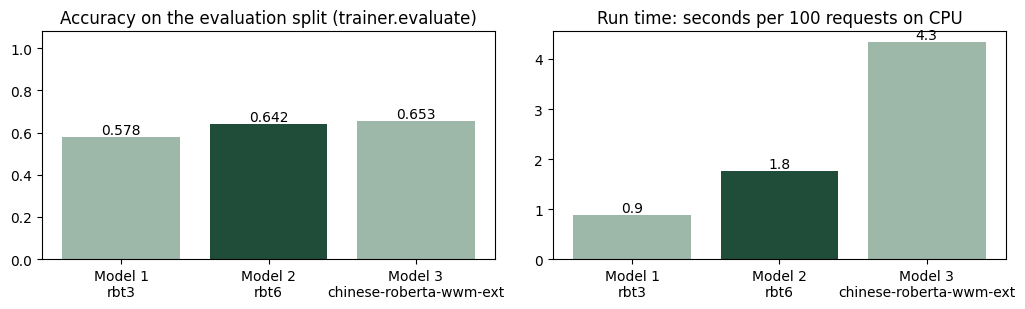

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.2))
names = [f"{c}\n{b.split('/')[-1]}" for c, b in CANDIDATES.items()]
colors = ["#1F4D3A" if b == CHOSEN else "#9DB8A9" for b in CANDIDATES.values()]
ax[0].bar(names, table.eval_accuracy, color=colors); ax[0].set_ylim(0, 1.08)
ax[0].set_title("Accuracy on the evaluation split (trainer.evaluate)")
for x, v in enumerate(table.eval_accuracy): ax[0].text(x, v + 0.015, f"{v:.3f}", ha="center")
ax[1].bar(names, table.cpu_seconds_per_100_requests, color=colors)
ax[1].set_title("Run time: seconds per 100 requests on CPU")
for x, v in enumerate(table.cpu_seconds_per_100_requests): ax[1].text(x, v, f"{v:.1f}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(OUT / "p1_comparison.png", dpi=150); plt.show()

## 5 · Final test on hand-written sentences

These 108 sentences played no part in training or in the choice above. All three models are listed for
transparency; the decision was already made in section 4.

In [10]:
final = pd.DataFrame({**baselines, **{b: results[b] for b in CANDIDATES.values()}}).T[["test_accuracy", "test_tag_accuracy", "test_macro_f1", "params_M"]].round(3)
final["picked"] = ["yes" if i == CHOSEN else "" for i in final.index]
final

,test_accuracy,test_tag_accuracy,test_macro_f1,params_M,picked
keyword lexicon (no model),0.648,0.954,0.821,0.000,
zero-shot mDeBERTa (no training),0.287,0.829,0.545,278.812,
hfl/rbt3,0.852,0.977,0.931,38.483,
hfl/rbt6,0.889,0.984,0.955,59.747,yes
hfl/chinese-roberta-wwm-ext,0.806,0.969,0.909,102.274,


In [11]:
chosen_pred = test_preds[CHOSEN]
per_tag = pd.DataFrame({
    "keyword F1": f1_score(Y_test, kw_test, average=None, zero_division=0),
    "fine-tuned F1": f1_score(Y_test, chosen_pred, average=None, zero_division=0),
    "test sentences with tag": Y_test.sum(0).astype(int)}, index=ALL_TAGS).round(3)
per_tag

,keyword F1,fine-tuned F1,test sentences with tag
steam,1.000,1.000,23
blanch,0.941,0.971,18
soup,1.000,0.980,25
stir,0.974,0.974,19
more_veg,0.714,0.829,18
more_meat,0.696,0.966,15
less_sweet,0.519,0.976,20
quick,0.727,0.947,20


In [12]:
def names(row):
    return ", ".join(t for t, v in zip(ALL_TAGS, row) if v) or "(none)"

detail = pd.DataFrame({"sentence": [r["text"] for r in p1_test], "expected": [names(y) for y in Y_test],
                       "predicted": [names(p) for p in chosen_pred]})
detail["correct"] = np.where(detail.expected == detail.predicted, "Correct", "Incorrect")
print((detail.correct == "Correct").sum(), "of", len(detail), "sentences fully correct")
detail[detail.correct == "Incorrect"]

96 of 108 sentences fully correct


,sentence,expected,predicted,correct
11,quick stir fry with lots of veggies,"stir, more_veg, quick","stir, more_veg",Incorrect
54,要有魚有菜,(none),more_veg,Incorrect
60,急，蒸,"steam, quick",steam,Incorrect
64,收工遲，淥個菜炒個蛋算,"blanch, stir, quick","stir, quick",Incorrect
67,a warm broth and blanched greens,"blanch, soup","blanch, more_veg",Incorrect
71,唔該整返啲家常小菜,(none),more_veg,Incorrect
77,唔好甜，唔好炒，蒸就得,"steam, less_sweet","steam, stir, less_sweet",Incorrect
79,啲男仔話要多肉少菜,more_meat,more_veg,Incorrect
82,想食住家菜,(none),more_veg,Incorrect
85,我想要有汁撈飯嘅餸,(none),less_sweet,Incorrect


## 6 · Save, record and upload the picked model

The folder `artifacts/same-table-tagger` is the model the Streamlit app loads (and the folder to submit as
"Fine-tuned model files").

In [13]:
import shutil

FINAL_DIR = OUT / "same-table-tagger"
shutil.rmtree(FINAL_DIR, ignore_errors=True); shutil.copytree(dirs[CHOSEN], FINAL_DIR)
(OUT / "p1_results.json").write_text(json.dumps({
    "dataset": {"labels": len(ALL_TAGS), "training": len(p1_train), "evaluation": len(p1_eval), "testing": len(p1_test)},
    "settings": {"epochs": EPOCHS, "learning_rate": LR, "batch_size": BATCH, "device": DEVICE},
    "candidates": CANDIDATES, "results": results, "baselines": baselines, "chosen": CHOSEN,
    "test_detail": detail.to_dict("records")}, ensure_ascii=False, indent=1), encoding="utf-8")

REPO_ID = f"{HF_USER}/same-table-tagger"
if PUSH_TO_HUB:
    AutoModelForSequenceClassification.from_pretrained(FINAL_DIR).push_to_hub(REPO_ID)
    AutoTokenizer.from_pretrained(FINAL_DIR).push_to_hub(REPO_ID)
    print("uploaded to https://huggingface.co/" + REPO_ID)
else:
    print("PUSH_TO_HUB is False. Model saved in", FINAL_DIR)
print(f'''
# Streamlit Cloud -> Settings -> Secrets
P1_MODEL_ID = "{REPO_ID}"
P1_TASK     = "text-classification"
''')

PUSH_TO_HUB is False. Model saved in /home/claude/same_table_app/artifacts/same-table-tagger

# Streamlit Cloud -> Settings -> Secrets
P1_MODEL_ID = "Tannedfish/same-table-tagger"
P1_TASK     = "text-classification"

